# This project explores the IBM Quantum Platform Build Your Own Quantum Computer Tutorial

## Basic Package Imports

In [ ]:
# Core Qiskit imports
from qiskit import QuantumCircuit
from qiskit.visualization import plot_histogram
from qiskit_aer import AerSimulator
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager

# IBM Runtime specific imports
from qiskit_ibm_runtime import SamplerV2 as Sampler, QiskitRuntimeService

# DotEnv and OS
from dotenv import load_dotenv
import os

## Environment Check

In [2]:
import sys

import qiskit
import qiskit_aer
import qiskit_ibm_runtime
import pylatexenc

print("Python:", sys.version.split()[0])
print("qiskit:", qiskit.__version__)
print("qiskit-aer:", qiskit_aer.__version__)
print("qiskit-ibm-runtime:", qiskit_ibm_runtime.__version__)
print("pylatexenc:", pylatexenc.__version__)

Python: 3.11.18
qiskit: 2.6.2
qiskit-aer: 0.18.2
qiskit-ibm-runtime: 0.52.1
pylatexenc: 2.11


## Basic Terminology

Superposition: A fundamental principle that allows quantum systems to exist in multiple states simulaneously. Once read, it will be measured as either 0 or 1.

Bell State: A type of maximally entangled quantum state involving two qubits that has non-classical correlations. Measuring one affects the state of the other.

Quantum Entanglement: A phenomenon in quantum mechanics where two or more particles become interconnected such that their states are correlated and one particle cannot be described independently of the state of another.

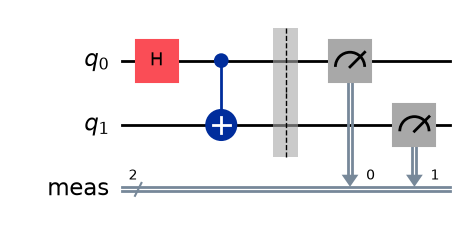

In [3]:
bell = QuantumCircuit(2)
bell.h(0)
bell.cx(0, 1)

bell.measure_all()
bell.draw("mpl")

In [4]:
def run_circuit_and_get_counts(circuit, backend, shots=1000):
    """
    Runs a quantum circuit on a specified backend and returns the measurement counts.

    Args:
        circuit (QuantumCircuit): The quantum circuit to run.
        backend: The Qiskit backend (real device or simulator).
        shots (int): The number of shots to run the circuit.

    Returns:
        dict: A dictionary of measurement counts.
    """
    pm = generate_preset_pass_manager(backend=backend, optimization_level=1)
    isa_circuit = pm.run(circuit)

    sampler = Sampler(mode=backend)

    job = sampler.run([isa_circuit], shots=shots)
    result = job.result()

    return result[0].data.meas.get_counts()

In [7]:
load_dotenv()
IBM_TOKEN = os.getenv("IBM_QUANTUM_TOKEN")

if not IBM_TOKEN:
    raise ValueError("IBM_QUANTUM_TOKEN not found in .env")

# Syntax for first saving your token.  Delete these lines after saving your credentials.
QiskitRuntimeService.save_account(
    channel="ibm_quantum_platform",
    token=IBM_TOKEN,
    overwrite=True,
    set_as_default=True,
)
service = QiskitRuntimeService(channel="ibm_quantum_platform")

# Load saved credentials
service = QiskitRuntimeService()

# Use the least busy backend, or uncomment the loading of a specific backend like "ibm_fez".
backend = service.least_busy(operational=True, simulator=False, min_num_qubits=127)
# backend = service.backend("ibm_fez")
print(backend.name)

qiskit_runtime_service.__init__:WARNING:2026-11-16 22:31:33,159: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default instance or passing it in directly to QiskitRuntimeService(). Alternatively, pass instance='auto' or save it to your account for auto-selection without warning.
qiskit_runtime_service.__init__:WARNING:2026-11-16 22:31:35,361: Instance was not set at service instantiation. Free and trial plan instances will be prioritized. Based on the following filters: (tags: None, region: us-east, eu-de), and available plans: (open), the available account instances are: open-instance. If you need a specific instance set it explicitly either by using a saved account with a saved default insta

ibm_marrakesh


qiskit_runtime_service.backends:WARNING:2026-11-16 22:31:40,965: Using instance: open-instance, plan: open


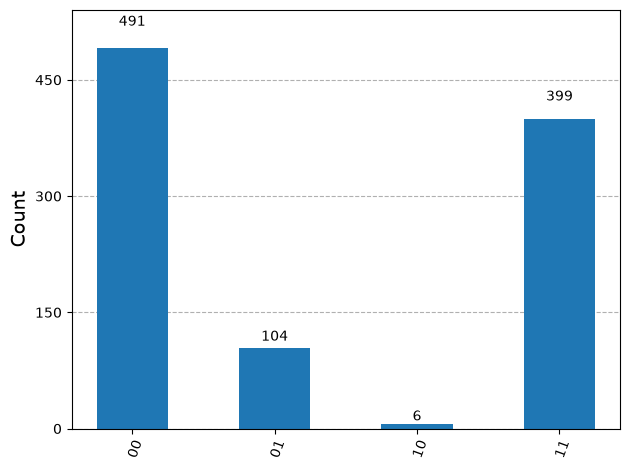

In [8]:
counts = run_circuit_and_get_counts(bell, backend, shots=1000)
plot_histogram(counts)

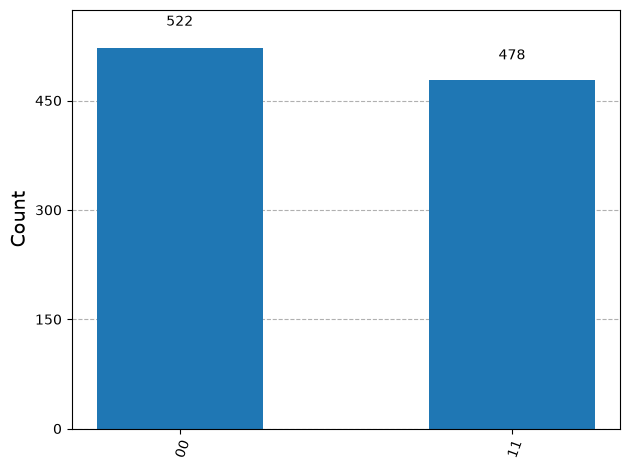

In [9]:
backend = AerSimulator()
counts = run_circuit_and_get_counts(bell, backend, shots=1000)

plot_histogram(counts)